# RQ2 | Which attributes show stronger within-group friendship?
Political orientation, religion and gender are measured on the same valid primary graphs using the categorical Coleman index. Zero means same-group ties match the group's share of the roster; positive means more same-group ties. The graph score weights group-specific scores by roster shares. It is **not the percentage of ties**. Numeric age uses a different statistic and is not ranked here.

This is an exploratory, descriptive addition to the [original analyses](01_primary_statistical_analysis.ipynb), not another test in the locked family of 24. No supplement, provider call or ledger is used.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis_figures/publication_v3.py').is_file())
def pinned_csv(rel, digest):
    data = (root / rel).read_bytes()
    assert hashlib.sha256(data).hexdigest() == digest, f'Primary input changed: {rel}'
    return pd.read_csv(BytesIO(data)).set_index('run_id', verify_integrity=True)

metrics = pinned_csv('outputs/final_study/060dcd3a86d5/main/network_metrics.csv',
                     'e6d6227c31cecd6dbb01ad34db8c32c9e0afe89c365d90c2872adc3e83f1b03a')
catalog = pinned_csv('outputs/analysis_ready/060dcd3a86d5/primary_valid_graphs.csv',
                     'f62db1d6ae788193af39005fd92a969d5418bd2d7fa1acef437577aa5edf5591')
assert len(metrics) == 896 and len(catalog) == 890 and catalog.cohort.eq('primary').all()
assert set(metrics.index[metrics.valid_graph]) == set(catalog.index)
attrs = ['Political orientation', 'Religion', 'Gender']
keys = ['method', 'model', 'culture', 'language']
rows = metrics.loc[catalog.index].rename(columns=dict(zip(
    ['coleman_political orientation', 'coleman_religion', 'coleman_gender'], attrs)))
defined = np.isfinite(rows[attrs]).all(axis=1)
assert (~defined).equals(catalog.empty_graph) and defined.sum() == 878
rows = rows.loc[defined, keys + attrs]
print('896 planned primary attempts | 6 failed | 890 valid | 12 empty | 878 scored | 0 supplements')

896 planned primary attempts | 6 failed | 890 valid | 12 empty | 878 scored | 0 supplements


## Compare like with like
First average each score across the available seeds **within** one model, generation method and instruction condition. Panel A gives the 28 resulting combinations per method equal weight. Panel B counts which attribute has the largest **unrounded** mean in each combination. This is not the fraction of people or graphs who chose a political friend.
The second score is the fraction of edges whose endpoints share the attribute minus the same fraction among all possible distinct roster pairs. Its unit is an absolute edge-share difference, not a Coleman unit. Neither score isolates one attribute from the others.

In [2]:
methods = ['global', 'local', 'sequential', 'iterative']
groups = rows.groupby(keys, sort=True)
cells = groups[attrs].mean()
n = groups.size()
assert len(cells) == 112 and cells.groupby(level='method').size().eq(28).all()
assert n.between(1, 8).all() and n.sum() == 878
assert cells.eq(cells.max(axis=1), axis=0).sum(axis=1).eq(1).all(), 'Tied leaders: do not break ties silently'
means = cells.groupby(level='method').mean().loc[methods]
leaders = cells.idxmax(axis=1)
wins = pd.crosstab(leaders.index.get_level_values('method'), leaders).reindex(index=methods, columns=attrs, fill_value=0)
assert wins.sum(axis=1).eq(28).all() and wins.sum().tolist() == [90, 22, 0]
display(pd.concat({'Mean Coleman score': means.round(3), 'Combinations ranked first': wins}, axis=1))

Mean Coleman score                 Combinations ranked first  \
           Political orientation Religion Gender     Political orientation   
global                     0.509    0.639  0.356                         6   
local                      0.579    0.249  0.174                        28   
sequential                 0.524    0.246  0.151                        28   
iterative                  0.714    0.126  0.129                        28   

                            
           Religion Gender  
global           22      0  
local             0      0  
sequential        0      0  
iterative         0      0

excess,political orientation,religion
method,,
global,1,27
iterative,28,0
local,28,0
sequential,28,0


,religion,Centrist,Left-leaning,Right-leaning
0,Buddhist,2,3,5
1,Christian,2,4,4
2,Hindu,3,3,4
3,Muslim,6,1,3
4,Nonreligious,3,6,1


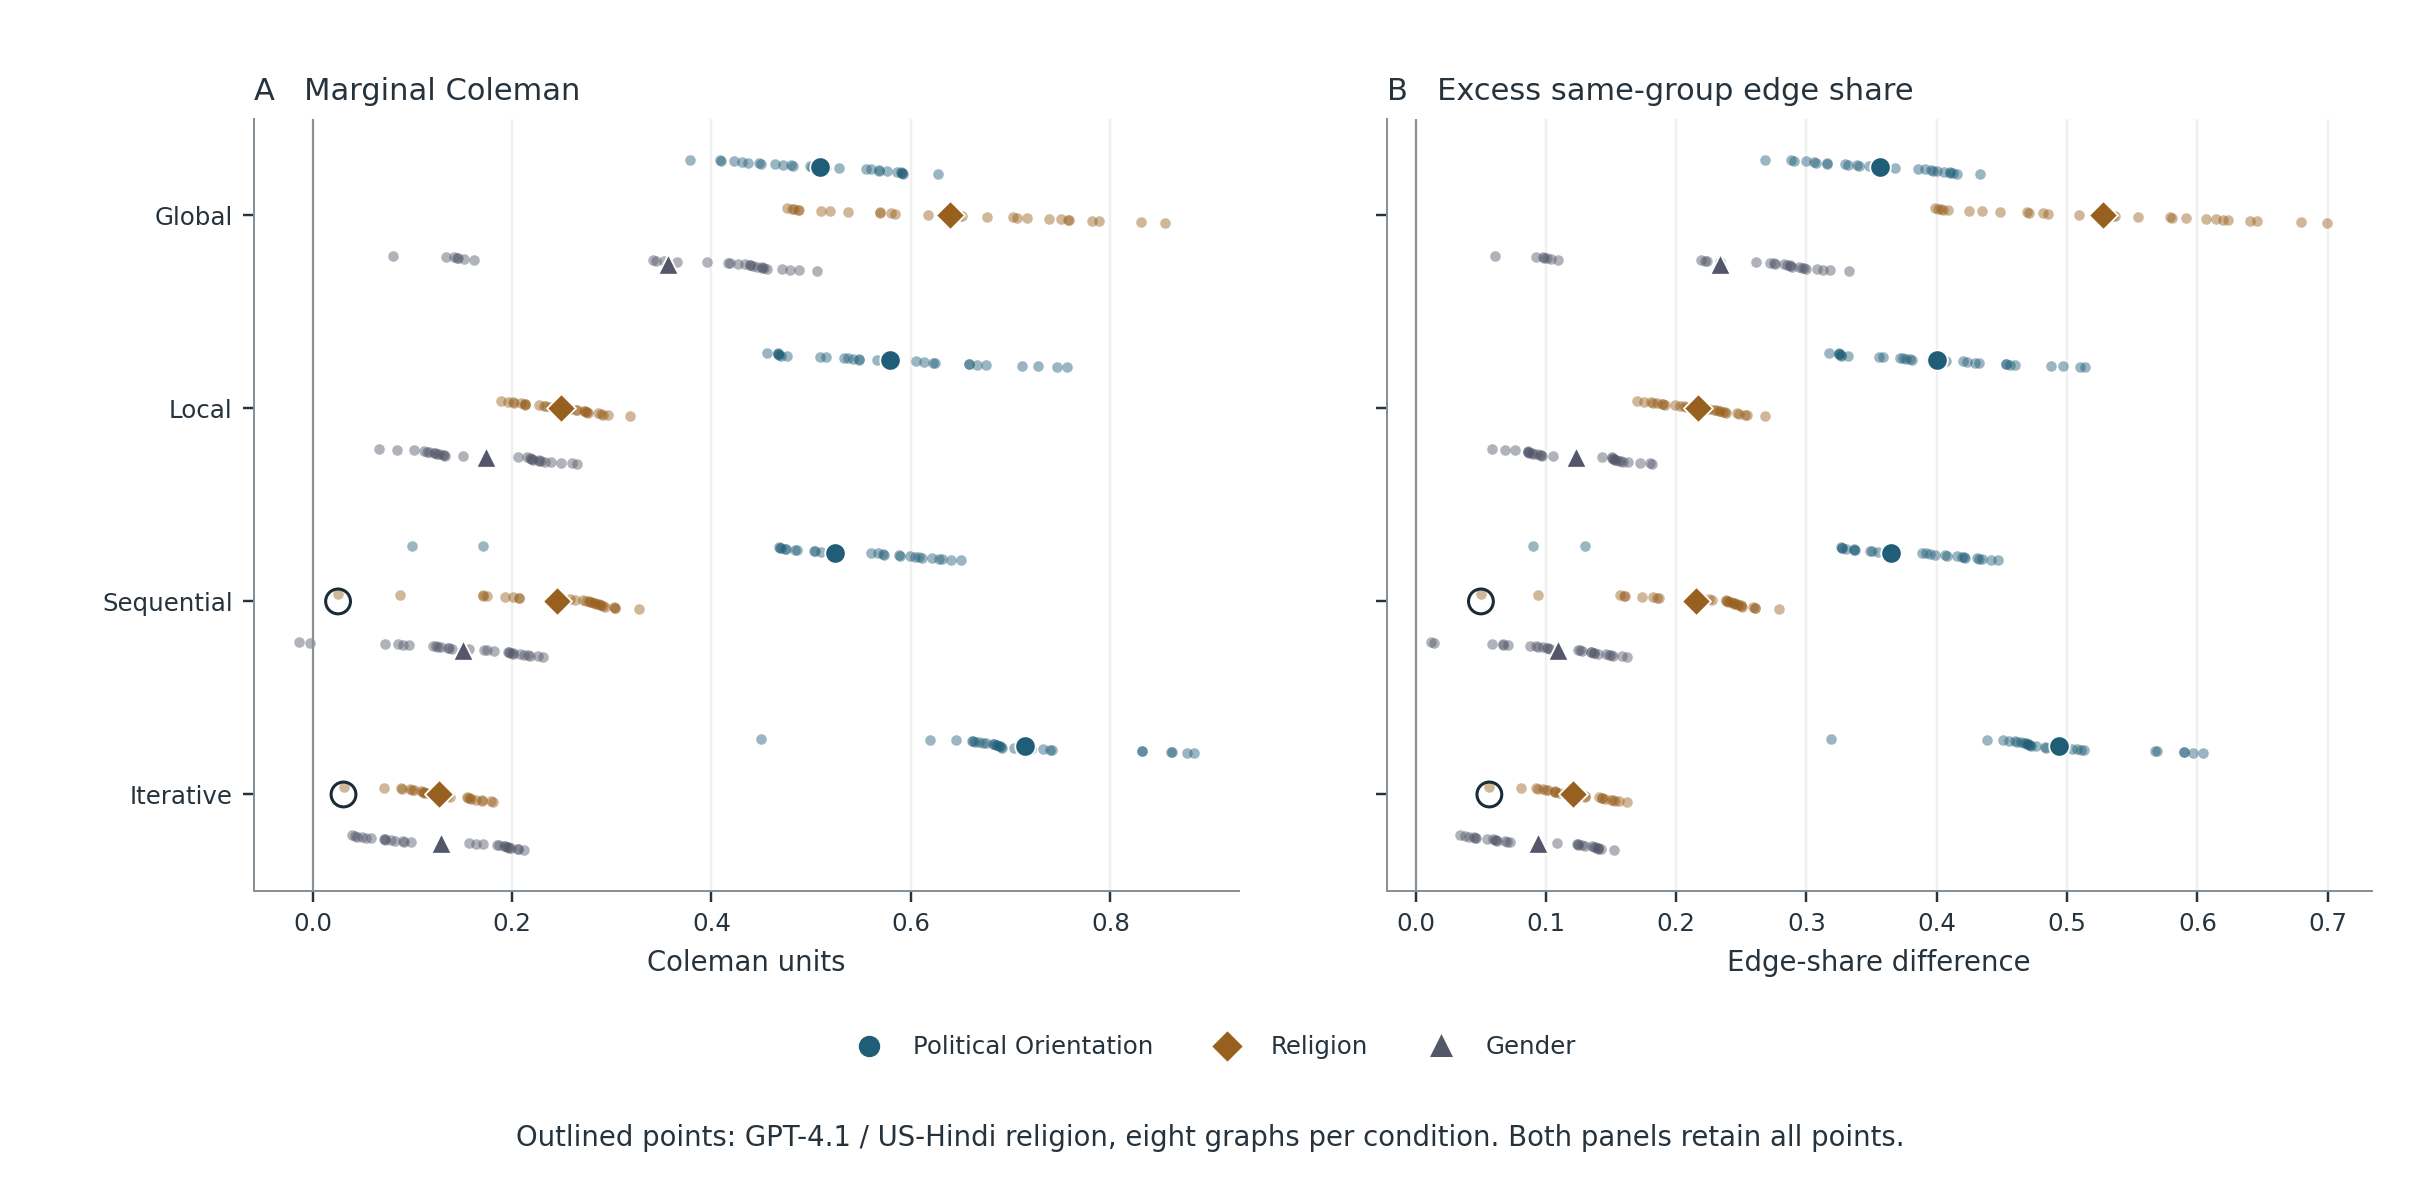

Both panels show all 28 model/instruction means per method and attribute. Large symbols are equal-combination means, not confidence intervals. Left: marginal Coleman. Right: excess same-attribute edge share above finite-roster chance. Axes have different units; neither is a causal importance scale. Outlined low-religion points are GPT-4.1 / US-Hindi, eight available graphs each: sequential Coleman 0.0256 and iterative 0.0310; no points were removed. Political-first counts (Coleman / excess): Global 6/28 / 1/28; each other method 28/28 / 28/28. Religion-politics association (V=0.316) describes this ONE designed roster, not independent evidence.

In [3]:
import sys
sys.path.insert(0, str(root))
from analysis_figures.review_v5 import show, table
published = table(root, 'attribute_cells').pivot(index=keys, columns='attribute', values='coleman')
np.testing.assert_allclose(cells[attrs], published[[a.lower() for a in attrs]].loc[cells.index], atol=1e-12, rtol=0)
ranks = table(root, 'attribute_ranks')
display(pd.crosstab(ranks.method, ranks.excess))
display(table(root, 'roster_crosstab'))
show(root, ['14_demographic_mixing'])

**Point to the Global row.** Political orientation leads in 6/28 Global combinations on Coleman, but only 1/28 on excess same-group edge share. Religion leads in the other 22 or 27. For each person-level procedure political orientation leads in 28/28 on both measures. Small points show all 28 condition means, not people or a confidence interval.

The fictional roster has three political categories, five religions and three genders with different shares. Politics and religion co-vary (descriptive Cramer's V = 0.316). The prompts present attributes in a fixed order. Neither changing that order nor independently varying roster associations was tested. The plot describes marginal mixing in generated graphs, not independent attribute importance or how people choose friends.
Both panels now display all 28 condition means on their own scoring scale. The outlined low-religion means in sequential and iterative are GPT-4.1 / US-Hindi (eight graphs each). They remain in the analysis; no outliers were removed.